# 🍷 Tech Challenge Fase 2 — Classificação da Qualidade de Vinhos
## Notebook 01 · Compreensão do Problema e Análise Exploratória (EDA)

**Objetivo do projeto:** prever se um vinho tinto é de **alta qualidade** (nota ≥ 7) a partir de suas características físico-químicas, apoiando enólogos e produtores na tomada de decisão durante a produção.

Este notebook cobre as etapas **1 (Compreensão do Problema)** e **2 (Análise Exploratória)** do desafio.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import FEATURES, FEATURE_LABELS_PT, QUALITY_COL, TARGET_COL, QUALITY_THRESHOLD, RESULTS_DIR
from src.data_loader import load_raw, add_binary_target
from src.visualization import (set_style, save_fig, CLASS_PALETTE, CLASS_LABELS,
                               COLOR_LOW, COLOR_HIGH, DIVERGING, INK_2)

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)

---
# 1. Compreensão do Problema

**Contexto.** A qualidade de um vinho é tradicionalmente avaliada por especialistas em análises sensoriais — um processo subjetivo, demorado e dependente da experiência do avaliador. Medidas físico-químicas, por outro lado, são objetivas, baratas e coletadas durante a produção. Se conseguirmos relacioná-las à nota dos especialistas, o produtor ganha um **sinal antecipado de qualidade**, podendo ajustar o processo antes do engarrafamento.

**Base de dados.** *Wine Quality Dataset* (vinho tinto, Vinho Verde — Portugal; Cortez et al., 2009). Cada linha é uma amostra de vinho com 11 medidas laboratoriais e a nota mediana de pelo menos 3 especialistas (escala 0–10).

**Variável alvo.** A nota original (`quality`) é transformada em uma **classificação binária**:

| Classe | Regra | Rótulo |
|---|---|---|
| 1 | `quality ≥ 7` | Alta qualidade |
| 0 | `quality < 7` | Baixa/Média qualidade |

**Pergunta de negócio:** *quais características separam um vinho excelente de um vinho comum — e conseguimos prever isso de forma confiável?*

In [2]:
raw = load_raw()
df = add_binary_target(raw)

print(f"Amostras: {df.shape[0]:,} | Variáveis preditoras: {len(FEATURES)}")
df.head()

Amostras: 1,599 | Variáveis preditoras: 11


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,high_quality
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,0
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,0
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,0
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0


In [3]:
# Transformação da nota em classe binária — conferência
pd.crosstab(df[QUALITY_COL], df[TARGET_COL].map(CLASS_LABELS), margins=True, margins_name="Total")

high_quality,Alta (≥ 7),Baixa/Média (< 7),Total
quality,,,
3,0,10,10
4,0,53,53
5,0,681,681
6,0,638,638
7,199,0,199
8,18,0,18
Total,217,1382,1599


---
# 2. Análise Exploratória de Dados

## 2.1 Visão geral, tipos e qualidade dos dados

In [4]:
info = pd.DataFrame({
    "tipo": df[FEATURES + [QUALITY_COL]].dtypes.astype(str),
    "nulos": df[FEATURES + [QUALITY_COL]].isna().sum(),
    "valores_unicos": df[FEATURES + [QUALITY_COL]].nunique(),
    "mín": df[FEATURES + [QUALITY_COL]].min(),
    "máx": df[FEATURES + [QUALITY_COL]].max(),
})
info

,tipo,nulos,valores_unicos,mín,máx
fixed acidity,float64,0,96,4.600,15.900
volatile acidity,float64,0,143,0.120,1.580
citric acid,float64,0,80,0.000,1.000
residual sugar,float64,0,91,0.900,15.500
chlorides,float64,0,153,0.012,0.611
free sulfur dioxide,float64,0,60,1.000,72.000
total sulfur dioxide,float64,0,144,6.000,289.000
density,float64,0,436,0.990,1.004
pH,float64,0,89,2.740,4.010
sulphates,float64,0,96,0.330,2.000


In [5]:
n_dup = df.duplicated().sum()
print(f"Valores faltantes: {df.isna().sum().sum()}")
print(f"Linhas duplicadas: {n_dup} ({n_dup/len(df):.1%} da base)")
print(f"% de alta qualidade entre as duplicadas: {df[df.duplicated()][TARGET_COL].mean():.1%} "
      f"(base inteira: {df[TARGET_COL].mean():.1%})")

# Checagens de consistência de domínio
checks = {
    "Valores negativos": (df[FEATURES] < 0).any(axis=1).sum(),
    "SO₂ livre > SO₂ total (impossível)": (df["free sulfur dioxide"] > df["total sulfur dioxide"]).sum(),
    "pH fora de 2,5–4,5": (~df["pH"].between(2.5, 4.5)).sum(),
    "Densidade fora de 0,98–1,01 g/cm³": (~df["density"].between(0.98, 1.01)).sum(),
    "Teor alcoólico fora de 8–16%": (~df["alcohol"].between(8, 16)).sum(),
}
pd.Series(checks, name="registros").to_frame()

Valores faltantes: 0
Linhas duplicadas: 240 (15.0% da base)
% de alta qualidade entre as duplicadas: 13.8% (base inteira: 13.6%)


,registros
Valores negativos,0
SO₂ livre > SO₂ total (impossível),0
"pH fora de 2,5–4,5",0
"Densidade fora de 0,98–1,01 g/cm³",0
Teor alcoólico fora de 8–16%,0


**Leitura:**
- **Não há valores faltantes** nem valores fisicamente impossíveis (negativos, SO₂ livre maior que o total, pH/densidade/álcool fora de faixas plausíveis para vinho tinto).
- Existem **240 linhas duplicadas (15%)**. Como as medidas são contínuas com várias casas decimais, duplicatas exatas indicam provavelmente **o mesmo lote registrado mais de uma vez**. A proporção de vinhos de alta qualidade entre elas (~14%) é igual à da base, então não distorcem a classe — mas, se mantidas, podem **vazar informação entre treino e teste** (a mesma amostra aparecendo nos dois lados). O tratamento será feito na etapa de pré-processamento.

## 2.2 Balanceamento das classes

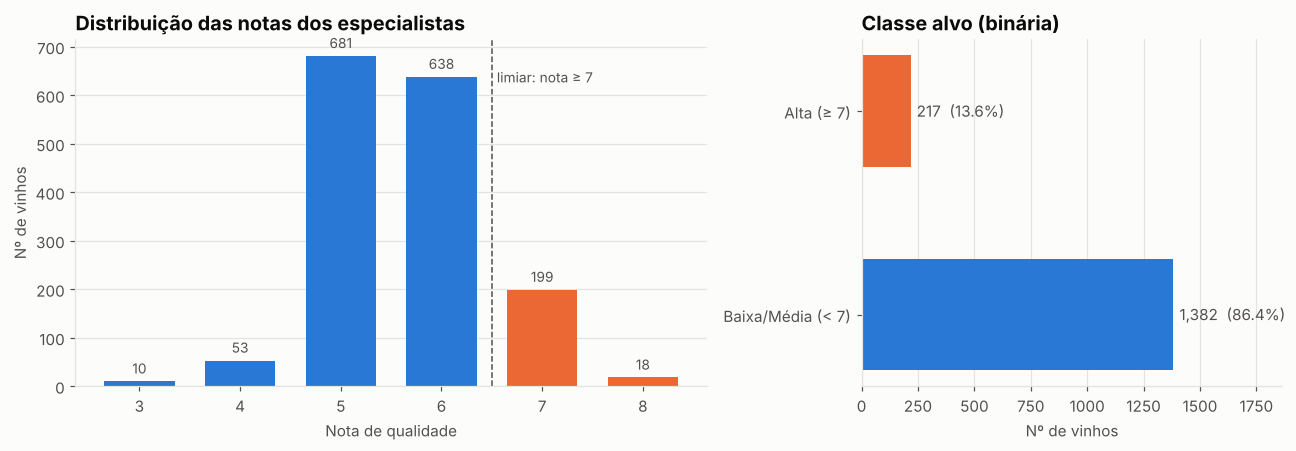

Razão de desbalanceamento: 6.4 vinhos comuns para cada vinho de alta qualidade


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})

q = df[QUALITY_COL].value_counts().sort_index()
colors = [COLOR_HIGH if v >= QUALITY_THRESHOLD else COLOR_LOW for v in q.index]
bars = axes[0].bar(q.index.astype(str), q.values, color=colors, width=0.7)
axes[0].bar_label(bars, padding=3, color=INK_2, fontsize=9)
axes[0].axvline(3.5, color=INK_2, ls="--", lw=1)
axes[0].text(3.55, q.max()*0.92, "limiar: nota ≥ 7", color=INK_2, fontsize=9)
axes[0].set(title="Distribuição das notas dos especialistas", xlabel="Nota de qualidade", ylabel="Nº de vinhos")
axes[0].grid(axis="x", visible=False)

c = df[TARGET_COL].value_counts().sort_index()
bars = axes[1].barh([CLASS_LABELS[i] for i in c.index], c.values, color=[CLASS_PALETTE[i] for i in c.index], height=0.55)
axes[1].bar_label(bars, labels=[f"{v:,}  ({v/c.sum():.1%})" for v in c.values], padding=4, color=INK_2)
axes[1].set(title="Classe alvo (binária)", xlabel="Nº de vinhos", xlim=(0, c.max()*1.35))
axes[1].grid(axis="y", visible=False)

plt.tight_layout(); save_fig(fig, "01_balanceamento_classes"); plt.show()

ratio = c[0] / c[1]
print(f"Razão de desbalanceamento: {ratio:.1f} vinhos comuns para cada vinho de alta qualidade")

**Leitura:**
- As notas se concentram em **5 e 6 (82% da base)**; notas extremas (3, 4 e 8) são raras. Nenhum vinho recebeu nota abaixo de 3 ou acima de 8.
- Após a binarização, apenas **13,6% dos vinhos são de alta qualidade** — uma razão de ~6,4 : 1.

**Implicações para a modelagem:**
1. **Acurácia é enganosa**: um modelo que sempre diz "baixa/média" acertaria 86% e não teria utilidade. Usaremos **Precisão, Recall, F1 e PR-AUC** da classe positiva, além de ROC-AUC.
2. A divisão treino/teste deve ser **estratificada** para preservar a proporção.
3. Será necessário compensar o desbalanceamento (pesos de classe e/ou ajuste do limiar de decisão).

## 2.3 Distribuição das variáveis

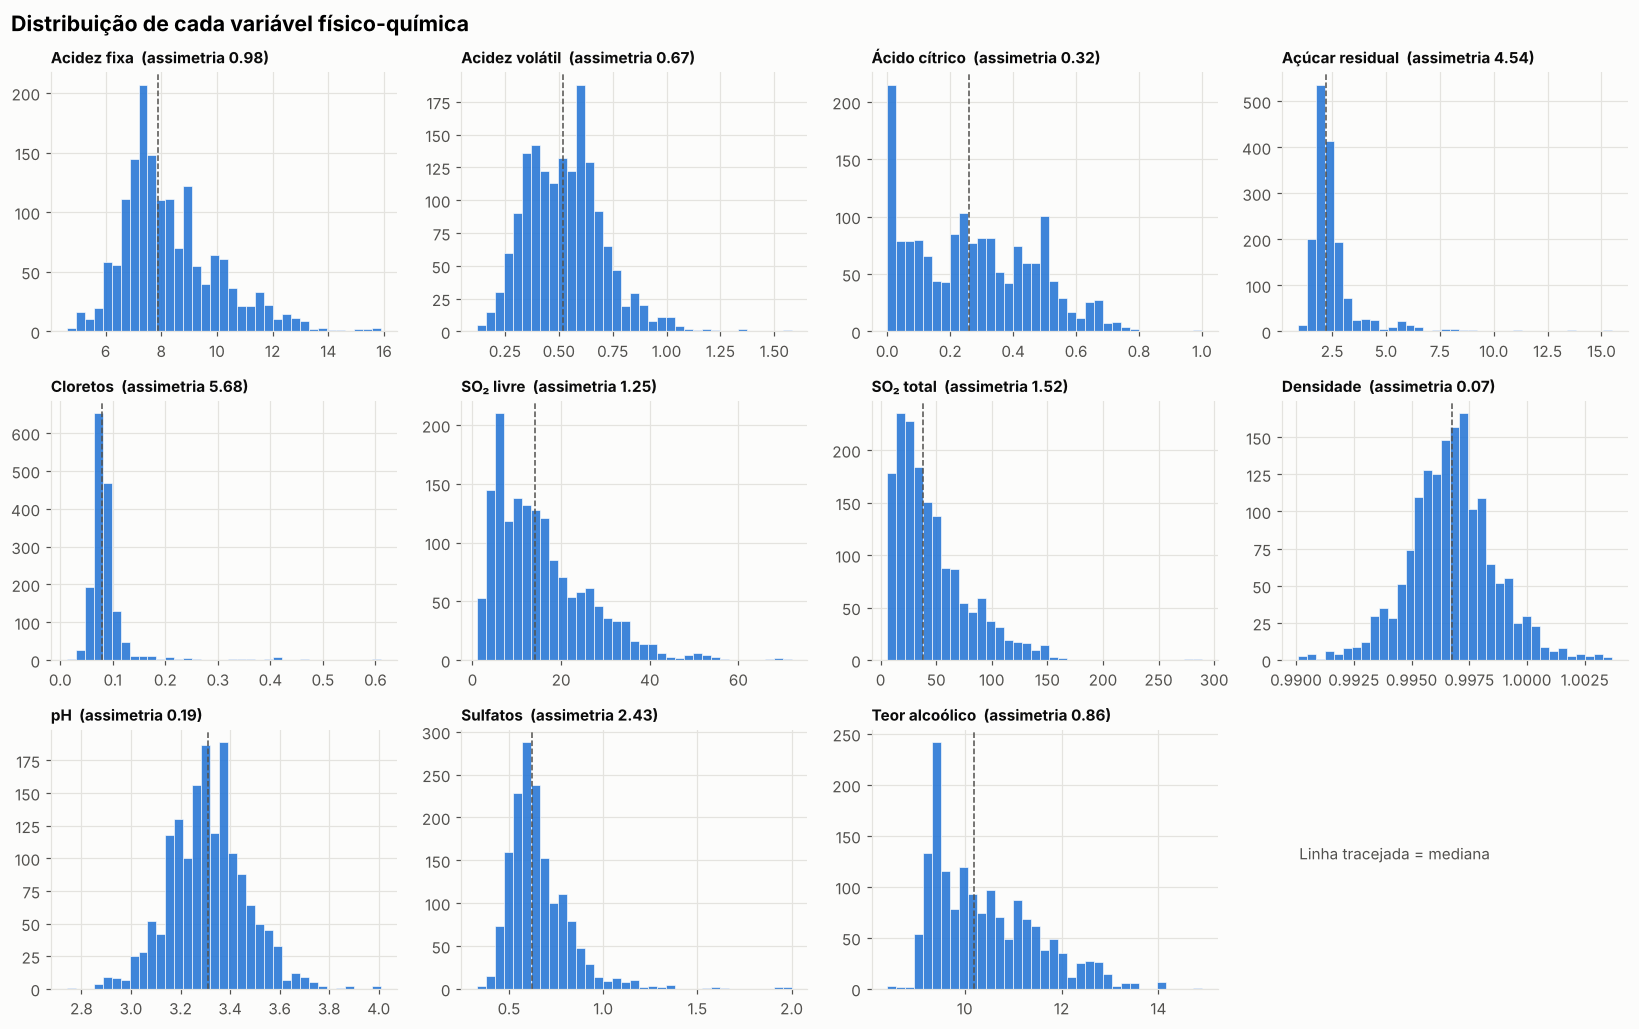

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], bins=35, ax=ax, color=COLOR_LOW, edgecolor="white", linewidth=0.4, alpha=0.9)
    ax.axvline(df[col].median(), color=INK_2, ls="--", lw=1)
    ax.set_title(f"{FEATURE_LABELS_PT[col]}  (assimetria {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[-1].axis("off")
axes.flat[-1].text(0.05, 0.5, "Linha tracejada = mediana", color=INK_2, fontsize=10)
fig.suptitle("Distribuição de cada variável físico-química", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); save_fig(fig, "02_distribuicoes"); plt.show()

In [8]:
dist = pd.DataFrame({
    "média": df[FEATURES].mean(),
    "mediana": df[FEATURES].median(),
    "desvio": df[FEATURES].std(),
    "assimetria": df[FEATURES].skew(),
    "curtose": df[FEATURES].kurt(),
}).rename(index=FEATURE_LABELS_PT)
dist["forma"] = np.select(
    [dist["assimetria"].abs() < 0.5, dist["assimetria"].abs() < 1],
    ["aprox. simétrica", "assimetria moderada"], "assimetria forte (cauda à direita)")
dist.sort_values("assimetria", ascending=False)

,média,mediana,desvio,assimetria,curtose,forma
Cloretos,0.087,0.079,0.047,5.680,41.716,assimetria forte (cauda à direita)
Açúcar residual,2.539,2.200,1.410,4.541,28.618,assimetria forte (cauda à direita)
Sulfatos,0.658,0.620,0.170,2.429,11.720,assimetria forte (cauda à direita)
SO₂ total,46.468,38.000,32.895,1.516,3.810,assimetria forte (cauda à direita)
SO₂ livre,15.875,14.000,10.460,1.251,2.024,assimetria forte (cauda à direita)
Acidez fixa,8.320,7.900,1.741,0.983,1.132,assimetria moderada
Teor alcoólico,10.423,10.200,1.066,0.861,0.200,assimetria moderada
Acidez volátil,0.528,0.520,0.179,0.672,1.226,assimetria moderada
Ácido cítrico,0.271,0.260,0.195,0.318,-0.789,aprox. simétrica
pH,3.311,3.310,0.154,0.194,0.807,aprox. simétrica


**Leitura:**
- **Aproximadamente simétricas:** densidade, pH e ácido cítrico — comportam-se perto de uma normal.
- **Assimetria forte à direita:** cloretos (5,7), açúcar residual (4,5), sulfatos (2,4), SO₂ total e livre. A maioria dos vinhos tem valores baixos e poucos têm valores muito altos — por exemplo, o açúcar residual mediano é 2,2 g/dm³, mas chega a 15,5.
- As variáveis estão em **escalas muito diferentes** (densidade varia na 3ª casa decimal; SO₂ total vai até 289). Modelos sensíveis a escala (como Regressão Logística) exigirão **padronização**, e as variáveis de cauda longa são candidatas a **transformação logarítmica**.

## 2.4 Comparação das variáveis entre as classes

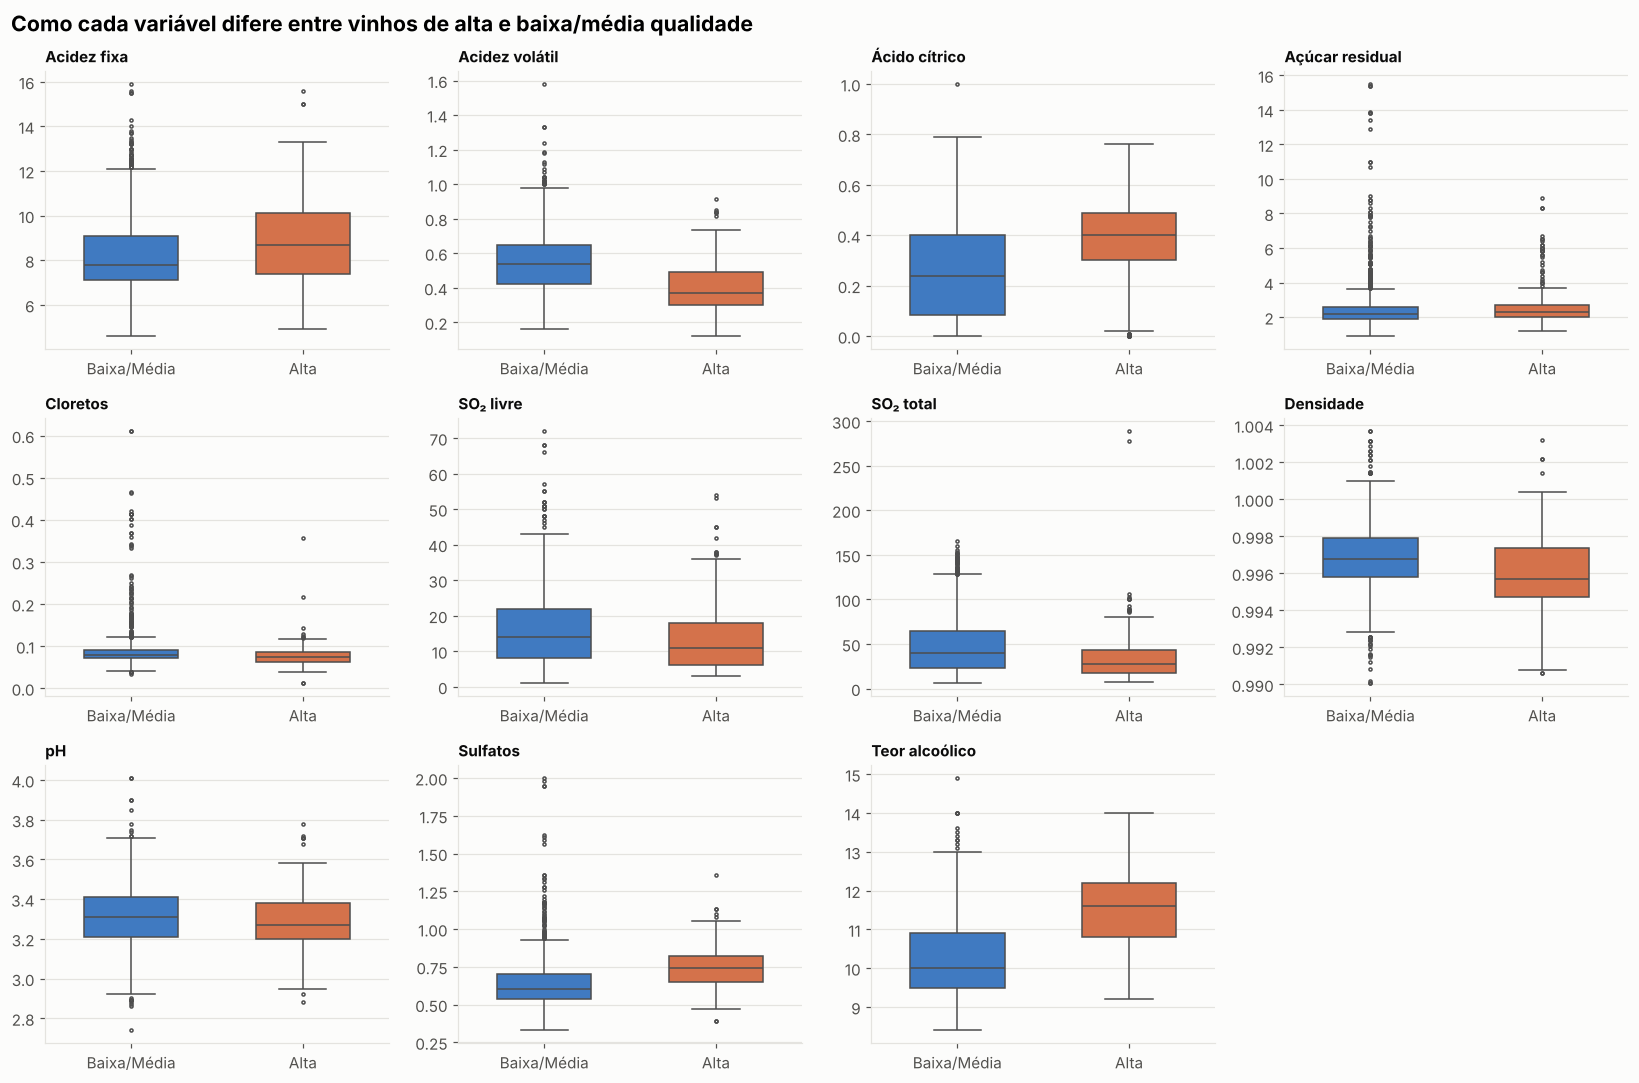

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
plot_df = df.assign(classe=df[TARGET_COL].map(CLASS_LABELS))
order = [CLASS_LABELS[0], CLASS_LABELS[1]]
pal = {CLASS_LABELS[k]: v for k, v in CLASS_PALETTE.items()}
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=plot_df, x="classe", y=col, hue="classe", order=order, palette=pal, ax=ax,
                width=0.55, fliersize=2, linewidth=1, legend=False)
    ax.set_title(FEATURE_LABELS_PT[col], fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks([0, 1], ["Baixa/Média", "Alta"])
axes.flat[-1].axis("off")
fig.suptitle("Como cada variável difere entre vinhos de alta e baixa/média qualidade",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); save_fig(fig, "03_boxplots_por_classe"); plt.show()

In [10]:
# Teste de Mann-Whitney (não paramétrico — adequado às distribuições assimétricas)
rows = []
for col in FEATURES:
    a = df.loc[df[TARGET_COL] == 1, col]; b = df.loc[df[TARGET_COL] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rbc = 2 * u / (len(a) * len(b)) - 1   # rank-biserial: tamanho de efeito (-1 a 1)
    rows.append({"variável": FEATURE_LABELS_PT[col], "mediana_baixa_media": b.median(), "mediana_alta": a.median(),
                 "variação_%": (a.median() / b.median() - 1) * 100, "efeito_rank_biserial": rbc, "p_valor": p})
diff = pd.DataFrame(rows).sort_values("efeito_rank_biserial", key=abs, ascending=False).reset_index(drop=True)
diff["significativo (p<0,05)"] = np.where(diff["p_valor"] < 0.05, "sim", "não")
diff.to_csv(RESULTS_DIR / "eda_diferencas_entre_classes.csv", index=False)
diff

,variável,mediana_baixa_media,mediana_alta,variação_%,efeito_rank_biserial,p_valor,"significativo (p<0,05)"
0,Teor alcoólico,10.000,11.600,16.000,0.645,0.000,sim
1,Acidez volátil,0.540,0.370,-31.481,-0.490,0.000,sim
2,Sulfatos,0.600,0.740,23.333,0.478,0.000,sim
3,Ácido cítrico,0.240,0.400,66.667,0.356,0.000,sim
4,SO₂ total,39.500,27.000,-31.646,-0.290,0.000,sim
5,Cloretos,0.080,0.073,-8.750,-0.265,0.000,sim
6,Densidade,0.997,0.996,-0.108,-0.255,0.000,sim
7,Acidez fixa,7.800,8.700,11.538,0.210,0.000,sim
8,SO₂ livre,14.000,11.000,-21.429,-0.150,0.000,sim
9,pH,3.310,3.270,-1.208,-0.112,0.008,sim


**Leitura — o "perfil" de um vinho de alta qualidade:**

Comparando as medianas, vinhos de alta qualidade têm:
- **Mais álcool** (11,6% vs 10,0%) — maior diferença entre as classes.
- **Menos acidez volátil** (0,37 vs 0,54 g/dm³, cerca de −31%).
- **Mais sulfatos** (0,74 vs 0,60) e **mais ácido cítrico** (0,40 vs 0,24).
- **Menos SO₂ total** (27 vs 39,5 mg/dm³), menos cloretos e densidade levemente menor.

Açúcar residual, pH e SO₂ livre têm diferença estatisticamente significativa, mas com **efeito pequeno** (|rank-biserial| ≤ 0,15) — baixo poder de separação isolado. Com ~1.600 amostras, até diferenças mínimas viram "significativas"; por isso olhamos o tamanho do efeito, não só o p-valor.

## 2.5 Correlações

Usamos **Spearman** (baseada em postos) porque várias variáveis são assimétricas e têm outliers, e porque a nota de qualidade é **ordinal** — Spearman captura relações monotônicas sem supor linearidade.

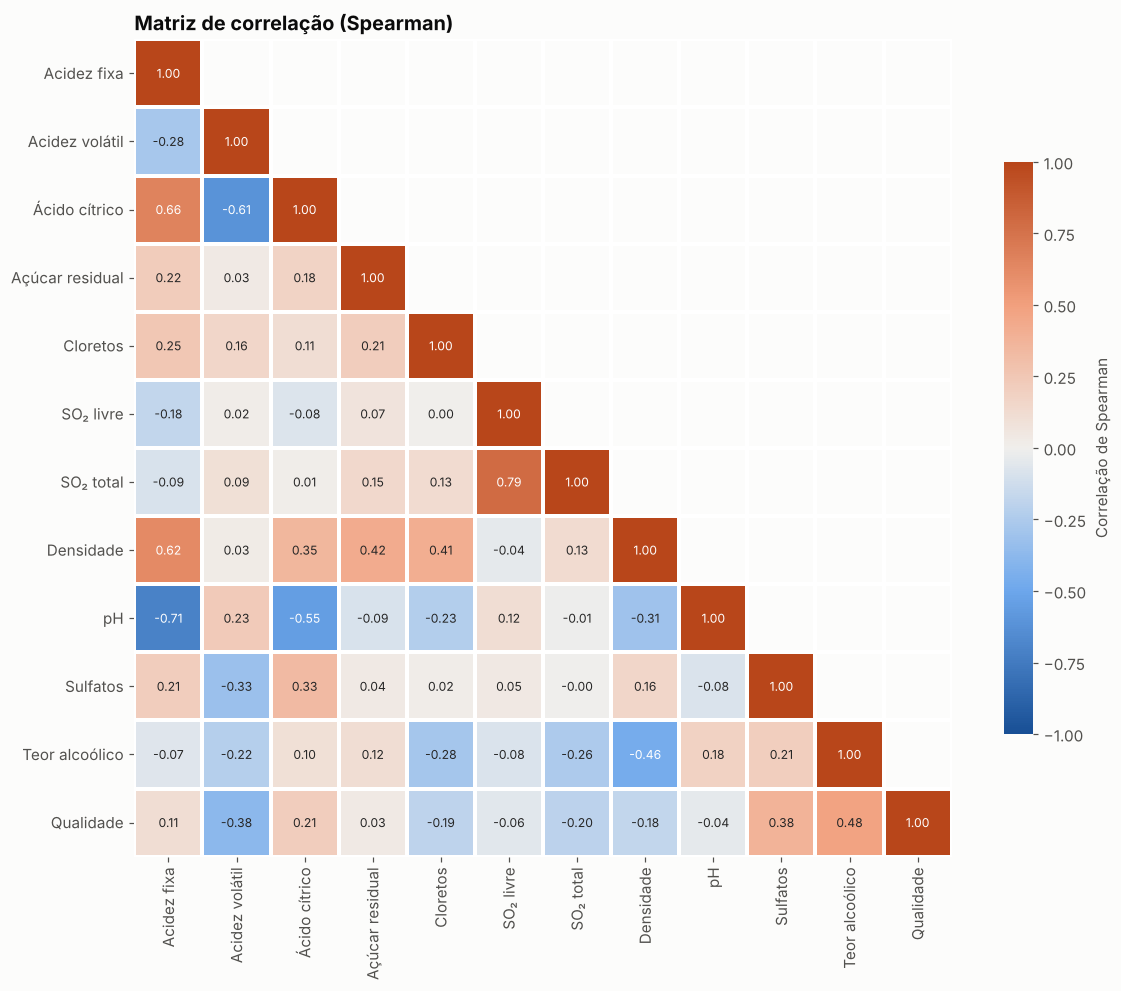

In [11]:
corr = df[FEATURES + [QUALITY_COL]].corr(method="spearman").rename(index=FEATURE_LABELS_PT, columns=FEATURE_LABELS_PT)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "Correlação de Spearman"}, ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação (Spearman)")
plt.tight_layout(); save_fig(fig, "04_matriz_correlacao"); plt.show()

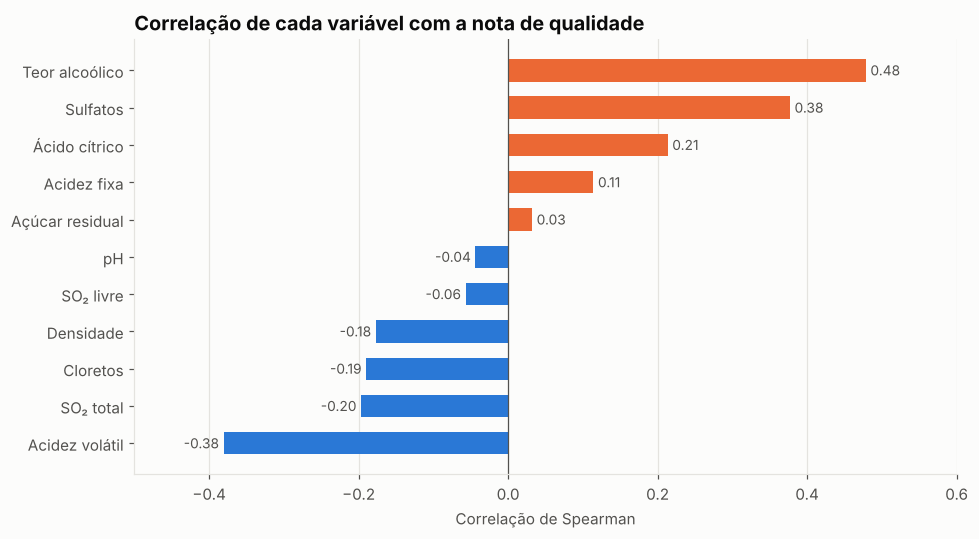

In [12]:
corr_target = (df[FEATURES + [QUALITY_COL]].corr(method="spearman")[QUALITY_COL]
               .drop(QUALITY_COL).sort_values())
fig, ax = plt.subplots(figsize=(9, 5))
cols = [COLOR_HIGH if v > 0 else COLOR_LOW for v in corr_target.values]
bars = ax.barh([FEATURE_LABELS_PT[i] for i in corr_target.index], corr_target.values, color=cols, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, color=INK_2, fontsize=9)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set(title="Correlação de cada variável com a nota de qualidade", xlabel="Correlação de Spearman",
       xlim=(-0.5, 0.6))
ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "05_correlacao_com_qualidade"); plt.show()

In [13]:
# Pares de variáveis mais correlacionados entre si
c = df[FEATURES].corr(method="spearman")
pairs = (c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pairs["pearson"] = [df[a].corr(df[b]) for a, b in zip(pairs.var_1, pairs.var_2)]
pairs = pairs.reindex(pairs.spearman.abs().sort_values(ascending=False).index).head(8).reset_index(drop=True)
pairs[["var_1", "var_2"]] = pairs[["var_1", "var_2"]].replace(FEATURE_LABELS_PT)
pairs

,var_1,var_2,spearman,pearson
0,SO₂ livre,SO₂ total,0.790,0.668
1,Acidez fixa,pH,-0.707,-0.683
2,Acidez fixa,Ácido cítrico,0.662,0.672
3,Acidez fixa,Densidade,0.623,0.668
4,Acidez volátil,Ácido cítrico,-0.610,-0.552
5,Ácido cítrico,pH,-0.548,-0.542
6,Densidade,Teor alcoólico,-0.462,-0.496
7,Açúcar residual,Densidade,0.422,0.355


### Justificativa das correlações

**a) Correlações com a qualidade (o que importa para o alvo)**

| Variável | ρ | Por que faz sentido |
|---|---|---|
| **Teor alcoólico** | **+0,48** | Mais álcool resulta de uvas mais maduras (mais açúcar convertido na fermentação) e dá corpo e estrutura ao vinho — atributos valorizados na prova. É a variável mais associada à qualidade. |
| **Acidez volátil** | **−0,38** | É basicamente ácido acético. Em excesso dá aroma de vinagre — um defeito clássico — e indica contaminação bacteriana ou fermentação mal controlada. |
| **Sulfatos** | **+0,38** | Sulfato de potássio contribui para os níveis de SO₂, que atua como antimicrobiano e antioxidante, preservando aroma e frescor. |
| Ácido cítrico | +0,21 | Confere frescor e "vivacidade"; em pequenas quantidades melhora o equilíbrio. |
| SO₂ total | −0,20 | Em excesso, o SO₂ é perceptível no aroma (odor pungente) e mascara o aroma frutado. |
| Cloretos | −0,19 | Representam o teor de sal; podem conferir gosto salgado indesejado. |
| Densidade | −0,18 | Reflexo indireto do álcool: o etanol é menos denso que a água, então vinhos mais alcoólicos são menos densos. |
| Açúcar residual, pH, SO₂ livre | ≈ 0 | Variação pequena entre vinhos tintos secos; pouca relação monotônica com a nota. |

**b) Correlações entre as variáveis preditoras (multicolinearidade)**

| Par | ρ | Por que faz sentido |
|---|---|---|
| SO₂ livre × SO₂ total | +0,79 | O SO₂ livre é **parte** do SO₂ total (total = livre + combinado). |
| Acidez fixa × pH | −0,71 | pH mede a acidez: quanto mais ácidos, menor o pH. Relação química direta. |
| Acidez fixa × Ácido cítrico | +0,66 | O ácido cítrico é **um dos componentes** da acidez fixa (junto com tartárico e málico). |
| Acidez fixa × Densidade | +0,62 | Ácidos dissolvidos são mais densos que a água e aumentam a densidade do vinho. |
| Acidez volátil × Ácido cítrico | −0,61 | Bactérias que degradam o ácido cítrico produzem ácido acético; vinhos com mais cítrico preservado tendem a ser mais "limpos". |
| Ácido cítrico × pH | −0,55 | Mais ácido, menor pH. |
| Densidade × Teor alcoólico | −0,46 | Etanol (0,79 g/cm³) é mais leve que a água; mais álcool → menor densidade. |
| Densidade × Açúcar residual | +0,42 | Açúcar dissolvido é mais denso que a água (é assim que se mede o açúcar do mosto). |
| Densidade × Cloretos | +0,41 | Sais dissolvidos também aumentam a densidade. |

**Implicações:** dois pares passam de |0,7| — SO₂ livre × total (0,79) e acidez fixa × pH (−0,71) — e a **densidade** é praticamente uma "combinação" de álcool, açúcar, ácidos e sais. A multicolinearidade é **moderada**, totalmente explicada pela química do vinho. Ela não prejudica modelos baseados em árvores, mas torna instáveis os coeficientes da Regressão Logística (usaremos regularização e cuidado na interpretação). Também sugere features derivadas, como a **proporção SO₂ livre / SO₂ total**.

## 2.6 Outliers e valores atípicos

In [14]:
q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (df[FEATURES] < lower) | (df[FEATURES] > upper)
extreme = (df[FEATURES] < q1 - 3 * iqr) | (df[FEATURES] > q3 + 3 * iqr)

out = pd.DataFrame({
    "outliers (1,5×IQR)": is_out.sum(),
    "% da base": is_out.mean() * 100,
    "extremos (3×IQR)": extreme.sum(),
    "limite_superior": upper,
    "máximo": df[FEATURES].max(),
    "% alta qualidade entre outliers": [df.loc[is_out[c], TARGET_COL].mean() * 100 if is_out[c].any() else np.nan for c in FEATURES],
}).rename(index=FEATURE_LABELS_PT).sort_values("outliers (1,5×IQR)", ascending=False)
out.to_csv(RESULTS_DIR / "eda_outliers.csv")
print(f"Vinhos com pelo menos 1 outlier: {is_out.any(axis=1).sum()} ({is_out.any(axis=1).mean():.1%})")
out

Vinhos com pelo menos 1 outlier: 405 (25.3%)


,"outliers (1,5×IQR)",% da base,extremos (3×IQR),limite_superior,máximo,% alta qualidade entre outliers
Açúcar residual,155,9.694,88,3.650,15.500,20.000
Cloretos,112,7.004,67,0.120,0.611,8.929
Sulfatos,59,3.690,16,1.000,2.000,16.949
SO₂ total,55,3.440,2,122.000,289.000,3.636
Acidez fixa,49,3.064,5,12.350,15.900,22.449
Densidade,45,2.814,0,1.001,1.004,26.667
pH,35,2.189,2,3.685,4.010,20.000
SO₂ livre,30,1.876,4,42.000,72.000,13.333
Acidez volátil,19,1.188,1,1.015,1.580,0.000
Teor alcoólico,13,0.813,0,13.500,14.900,53.846


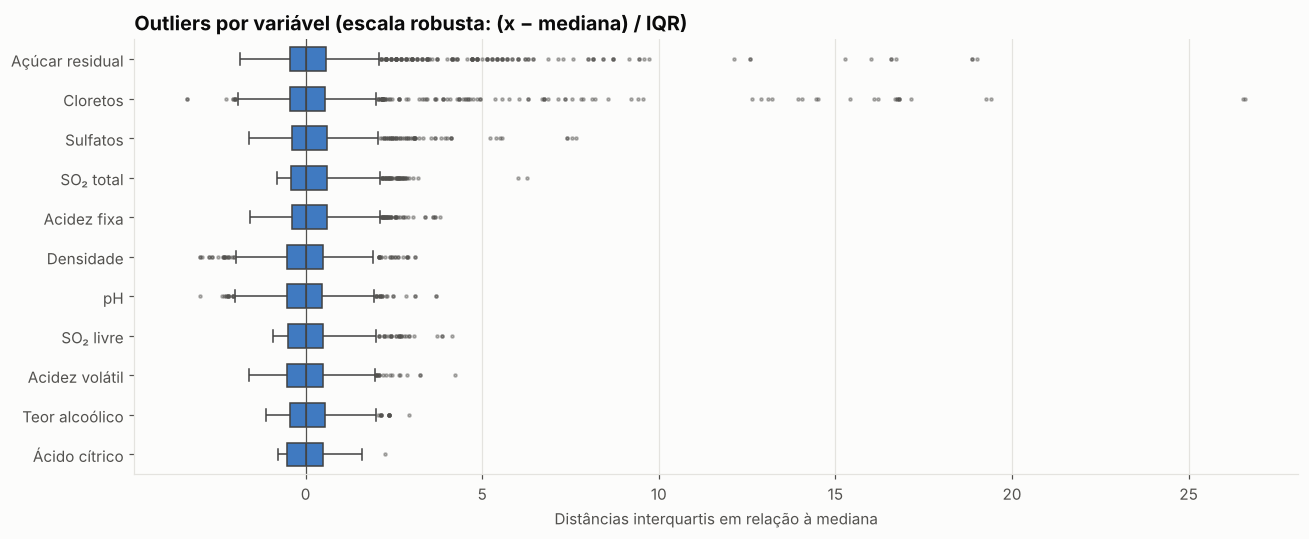

In [15]:
z = (df[FEATURES] - df[FEATURES].median()) / (df[FEATURES].quantile(0.75) - df[FEATURES].quantile(0.25))
z = z.rename(columns=FEATURE_LABELS_PT)
order = out.index.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=z[order], orient="h", color=COLOR_LOW, fliersize=2, linewidth=1, width=0.6, ax=ax,
            flierprops={"markerfacecolor": INK_2, "markeredgecolor": INK_2, "alpha": 0.4})
ax.axvline(0, color=INK_2, lw=0.8)
ax.set(title="Outliers por variável (escala robusta: (x − mediana) / IQR)", xlabel="Distâncias interquartis em relação à mediana")
ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "06_outliers"); plt.show()

**Leitura:**
- Pelo critério de 1,5×IQR, **25% dos vinhos têm ao menos um valor atípico**, concentrados em **açúcar residual, cloretos, sulfatos e SO₂ total** — exatamente as variáveis de cauda longa.
- Os valores, porém, são **quimicamente possíveis** (ex.: açúcar residual de 15,5 g/dm³ é um vinho mais doce; SO₂ total de 289 mg/dm³ é bem alto e merece atenção, mas não é fisicamente impossível). Não são erros de medição, e sim **vinhos genuinamente diferentes**.
- Remover 25% da base eliminaria informação real e muitos dos já escassos exemplos de alta qualidade. **Decisão para o pré-processamento:** manter os registros e reduzir a influência dos extremos com **transformação logarítmica** nas variáveis assimétricas (e/ou escalonamento robusto). Modelos de árvore já são naturalmente pouco sensíveis a outliers.

## 2.7 As duas variáveis mais importantes juntas

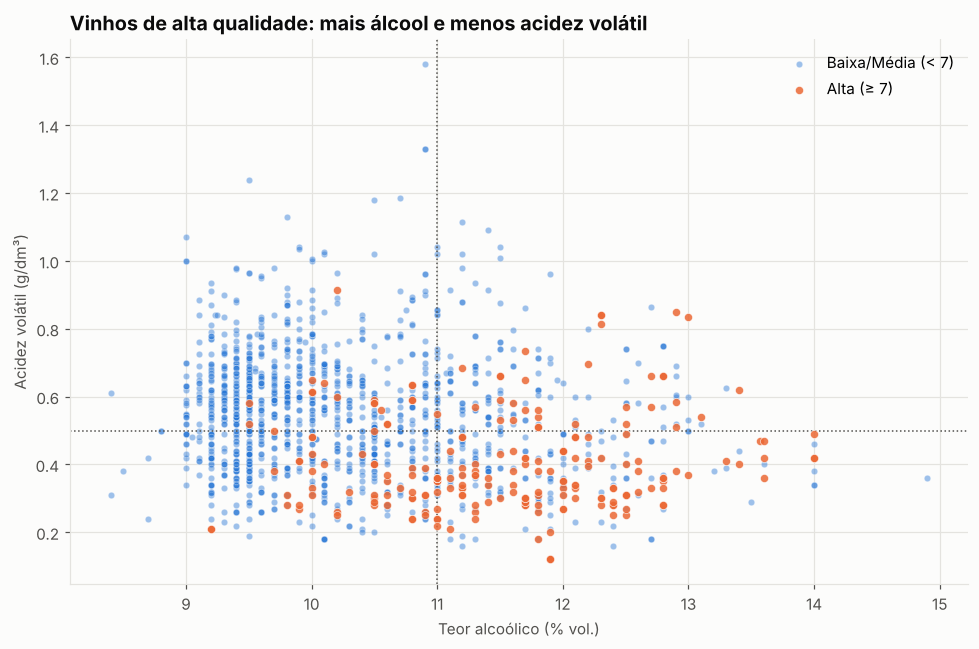

Vinhos com álcool ≥ 11% e acidez volátil ≤ 0,5: 290 — destes, 42% são de alta qualidade
Fora dessa zona: 7% são de alta qualidade


In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
for k in [0, 1]:
    s = df[df[TARGET_COL] == k]
    ax.scatter(s["alcohol"], s["volatile acidity"], s=18 if k == 0 else 28, alpha=0.45 if k == 0 else 0.85,
               color=CLASS_PALETTE[k], edgecolor="white", linewidth=0.4, label=CLASS_LABELS[k], zorder=2 + k)
ax.set(xlabel="Teor alcoólico (% vol.)", ylabel="Acidez volátil (g/dm³)",
       title="Vinhos de alta qualidade: mais álcool e menos acidez volátil")
ax.axvline(11, color=INK_2, ls=":", lw=1); ax.axhline(0.5, color=INK_2, ls=":", lw=1)
ax.legend(loc="upper right")
plt.tight_layout(); save_fig(fig, "07_alcool_vs_acidez_volatil"); plt.show()

zone = (df["alcohol"] >= 11) & (df["volatile acidity"] <= 0.5)
print(f"Vinhos com álcool ≥ 11% e acidez volátil ≤ 0,5: {zone.sum()} — destes, {df.loc[zone, TARGET_COL].mean():.0%} são de alta qualidade")
print(f"Fora dessa zona: {df.loc[~zone, TARGET_COL].mean():.0%} são de alta qualidade")

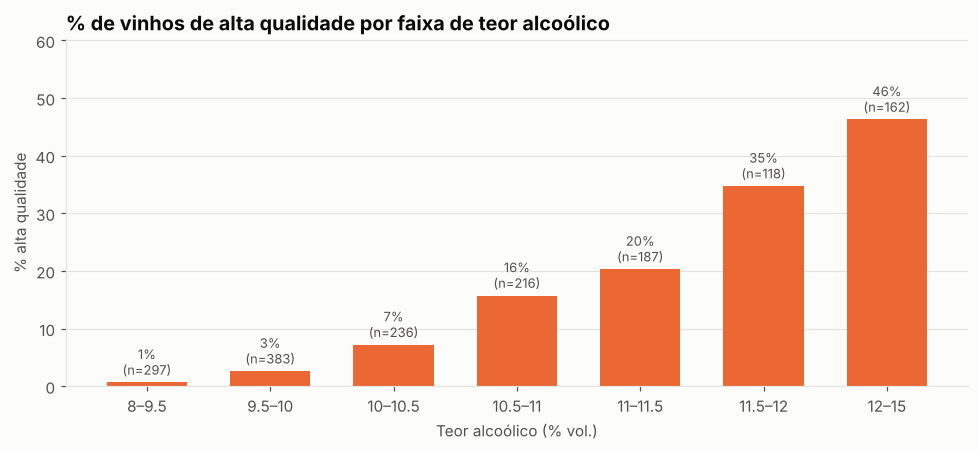

In [17]:
# Taxa de alta qualidade por faixa de teor alcoólico
bins = pd.cut(df["alcohol"], [8, 9.5, 10, 10.5, 11, 11.5, 12, 15], right=False)
rate = df.groupby(bins, observed=True)[TARGET_COL].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [f"{i.left:g}–{i.right:g}" for i in rate.index]
bars = ax.bar(labels, rate["mean"] * 100, color=COLOR_HIGH, width=0.65)
ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n})" for m, n in zip(rate["mean"], rate["size"])], padding=3, color=INK_2, fontsize=8.5)
ax.set(title="% de vinhos de alta qualidade por faixa de teor alcoólico", xlabel="Teor alcoólico (% vol.)",
       ylabel="% alta qualidade", ylim=(0, rate["mean"].max() * 100 * 1.3))
ax.grid(axis="x", visible=False)
plt.tight_layout(); save_fig(fig, "08_taxa_alta_qualidade_por_alcool"); plt.show()

---
## 2.8 Resumo dos principais insights da EDA

1. **Base limpa, mas com duplicatas.** Sem valores faltantes nem inconsistências físicas; 240 registros duplicados (15%) serão tratados para evitar vazamento entre treino e teste.
2. **Classe rara.** Só **13,6%** dos vinhos são de alta qualidade (~1 em cada 7). Métricas e treinamento precisam considerar esse desbalanceamento.
3. **Álcool é o principal sinal.** Abaixo de 10% de álcool, só ~2% dos vinhos são de alta qualidade; acima de 12%, quase metade (46%) é.
4. **Acidez volátil é o principal "defeito".** Vinhos excelentes têm ~31% menos acidez volátil (aroma de vinagre).
5. **Sulfatos e ácido cítrico ajudam;** SO₂ total, cloretos e densidade atrapalham.
6. **Açúcar residual, pH e SO₂ livre** têm pouca relação com a qualidade isoladamente.
7. **Multicolinearidade moderada**: os pares mais fortes são SO₂ livre × total (0,79) e acidez fixa × pH (−0,71), todos explicados pela química do vinho (componentes da acidez, SO₂ livre ⊂ total, álcool × densidade).
8. **Outliers são reais**, não erros — serão mantidos, com transformação log nas variáveis de cauda longa.

➡️ **Próximo passo:** pré-processamento (notebook 02).